# Video -- Frame Prediction / Short Video Generation
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 3. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Video -- Frame Prediction / Short Video Generation](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 3. Video -- Frame Prediction / Short Video Generation
### Problem: given a short context clip, generate a plausible continuation -- new frames the model has never seen.

### 3.1 Problem Statement & Why this Architecture

Video adds a temporal dimension on top of images: the model must capture **motion**, not just appearance. A **ConvLSTM** (convolutional LSTM) is a natural from-scratch architecture -- it keeps the LSTM's ability to model a sequence, but replaces the fully-connected gates with convolutions, so hidden state stays **spatial** (it knows *where* things are, not just *that* something happened).

We use an **encoder-decoder ConvLSTM**: the encoder compresses a few context frames into a hidden state; the decoder then unrolls forward, autoregressively predicting future frames. This is the classic "next-frame prediction" formulation of video generation (Srivastava et al. 2015), and generalizes directly to full text-to-video diffusion models at scale (Section 3.5b).

### 3.2 Data Collection & Preparation


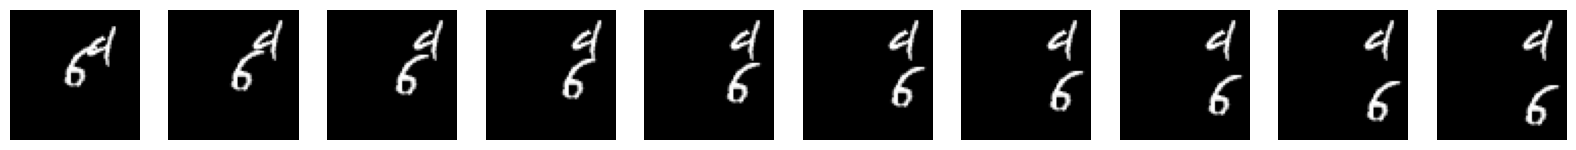

In [6]:
from torchvision.datasets import MNIST

mnist_digits = MNIST(root="data/video", train=True, download=True).data.numpy()  # [N,28,28] uint8


def make_moving_mnist_sequence(digit_imgs, canvas_size=64, seq_len=20, num_digits=2):
    # Classic synthetic "Moving MNIST" generator: place `num_digits` MNIST digits
    # on a larger canvas and bounce them off the walls with constant velocity.
    # Generating on the fly avoids downloading the ~700MB precomputed dataset.
    canvas = np.zeros((seq_len, canvas_size, canvas_size), dtype=np.float32)
    for _ in range(num_digits):
        digit = digit_imgs[np.random.randint(len(digit_imgs))].astype(np.float32) / 255.0
        h, w = digit.shape
        x = np.random.uniform(0, canvas_size - w)
        y = np.random.uniform(0, canvas_size - h)
        dx = np.random.choice([-1, 1]) * np.random.uniform(2, 4)
        dy = np.random.choice([-1, 1]) * np.random.uniform(2, 4)
        for t in range(seq_len):
            if x < 0 or x + w > canvas_size:
                dx *= -1
            if y < 0 or y + h > canvas_size:
                dy *= -1
            x, y = np.clip(x + dx, 0, canvas_size - w), np.clip(y + dy, 0, canvas_size - h)
            xi, yi = int(x), int(y)
            canvas[t, yi:yi + h, xi:xi + w] = np.maximum(canvas[t, yi:yi + h, xi:xi + w], digit)
    return canvas  # [seq_len, H, W] in [0,1]


class MovingMNIST(Dataset):
    def __init__(self, digit_imgs, length=1500, seq_len=20, canvas_size=64):
        self.digit_imgs = digit_imgs
        self.length = length
        self.seq_len = seq_len
        self.canvas_size = canvas_size

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        seq = make_moving_mnist_sequence(self.digit_imgs, self.canvas_size, self.seq_len)
        return torch.from_numpy(seq).unsqueeze(1)  # [seq_len, 1, H, W]


VIDEO_SEQ_LEN, VIDEO_CONTEXT_LEN = 20, 10
video_dataset = MovingMNIST(mnist_digits, length=1500, seq_len=VIDEO_SEQ_LEN, canvas_size=64)
video_loader = DataLoader(video_dataset, batch_size=16, shuffle=True, num_workers=0)

sample_seq = video_dataset[0]
show_images(sample_seq[:10], ncols=10, cmap="gray")


### 3.3 Model Architecture


In [7]:
class ConvLSTMCell(nn.Module):
    # A ConvLSTM replaces the fully-connected gates of a standard LSTM with
    # convolutions, so hidden state stays spatial instead of collapsing each
    # frame into a flat vector -- this preserves *where* things are in the frame.
    def __init__(self, in_ch, hidden_ch, kernel_size=3):
        super().__init__()
        pad = kernel_size // 2
        self.hidden_ch = hidden_ch
        self.conv = nn.Conv2d(in_ch + hidden_ch, 4 * hidden_ch, kernel_size, padding=pad)

    def forward(self, x, state):
        h, c = state
        combined = torch.cat([x, h], dim=1)
        gates = self.conv(combined)
        i, f, o, g = gates.chunk(4, dim=1)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

    def init_state(self, batch, spatial, device):
        return (torch.zeros(batch, self.hidden_ch, *spatial, device=device),
                torch.zeros(batch, self.hidden_ch, *spatial, device=device))


class ConvLSTMSeq2Seq(nn.Module):
    # Encoder ConvLSTM compresses the context frames into a hidden state;
    # the decoder ConvLSTM then unrolls forward, feeding its own predictions
    # back in (or ground truth, during training) to generate a short future video.
    def __init__(self, hidden_ch=32):
        super().__init__()
        self.encoder = ConvLSTMCell(1, hidden_ch)
        self.decoder = ConvLSTMCell(1, hidden_ch)
        self.out_conv = nn.Conv2d(hidden_ch, 1, 3, padding=1)

    def forward(self, context, n_future, teacher_frames=None):
        B, T, C, H, W = context.shape
        h, c = self.encoder.init_state(B, (H, W), context.device)
        for t in range(T):
            h, c = self.encoder(context[:, t], (h, c))

        preds = []
        last_frame = context[:, -1]
        for t in range(n_future):
            h, c = self.decoder(last_frame, (h, c))
            frame = torch.sigmoid(self.out_conv(h))
            preds.append(frame)
            # Teacher forcing: use ground truth as next input during training
            # (when available) instead of always feeding back our own prediction.
            last_frame = teacher_frames[:, t] if teacher_frames is not None else frame
        return torch.stack(preds, dim=1)  # [B, n_future, 1, H, W]


video_model = ConvLSTMSeq2Seq(hidden_ch=32).to(DEVICE)
count_parameters(video_model)


ConvLSTMSeq2Seq: 0.08M trainable parameters


76577

### 3.4 Loss Functions, Optimizers & Training Strategy

Per-pixel MSE between predicted and ground-truth future frames, with teacher forcing during training (feeding true past frames into the decoder) so early training isn't destabilized by the model's own bad early predictions.

### 3.5 Training Loop

**Calibrated to ~65s on a CUDA GPU** (5 epochs over 1500 synthetic sequences).


Video epoch 1/5:   0%|          | 0/94 [00:00<?, ?it/s]

Video epoch 1/5:   0%|          | 0/94 [00:00<?, ?it/s, loss=0.2397]

Video epoch 1/5:   1%|          | 1/94 [00:00<00:49,  1.90it/s, loss=0.2397]

Video epoch 1/5:   1%|          | 1/94 [00:00<00:49,  1.90it/s, loss=0.2367]

Video epoch 1/5:   2%|▏         | 2/94 [00:00<00:28,  3.22it/s, loss=0.2367]

...

Video epoch 5/5:  98%|█████████▊| 92/94 [00:15<00:00,  6.11it/s, loss=0.0039]

Video epoch 5/5:  99%|█████████▉| 93/94 [00:15<00:00,  6.08it/s, loss=0.0039]

Video epoch 5/5:  99%|█████████▉| 93/94 [00:15<00:00,  6.08it/s, loss=0.0030]

Video epoch 5/5: 100%|██████████| 94/94 [00:15<00:00,  6.52it/s, loss=0.0030]

Video epoch 5/5: 100%|██████████| 94/94 [00:15<00:00,  6.16it/s, loss=0.0030]

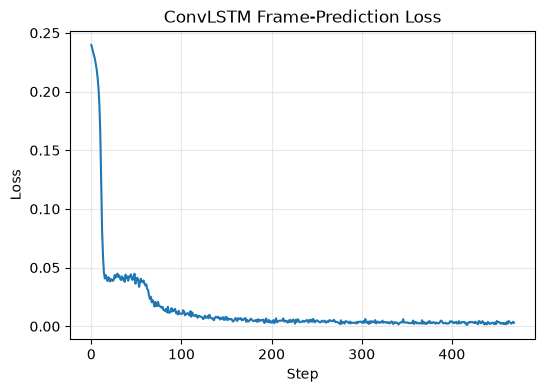

In [8]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
VIDEO_EPOCHS = 5
VIDEO_CKPT = "checkpoints/video_convlstm.pt"


def train_video_model(model, loader, epochs=VIDEO_EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    model.train()
    step = 0
    for epoch in range(epochs):
        pbar = tqdm(loader, desc=f"Video epoch {epoch + 1}/{epochs}")
        for seq in pbar:
            seq = seq.to(DEVICE)  # [B, seq_len, 1, H, W]
            context = seq[:, :VIDEO_CONTEXT_LEN]
            future = seq[:, VIDEO_CONTEXT_LEN:]
            preds = model(context, n_future=future.size(1), teacher_frames=future)
            loss = F.mse_loss(preds, future)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            history.append(loss.item())
            step += 1
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        save_checkpoint(model, optimizer, step, VIDEO_CKPT)
    return history


video_history = train_video_model(video_model, video_loader)
plot_loss(video_history, title="ConvLSTM Frame-Prediction Loss")


In [9]:
# (b) PRETRAINED / INFERENCE-ONLY PATH ---------------------------------------
# For genuine text-to-video generation, use a pretrained diffusion video model.
# (off by default -- installs `diffusers` and downloads a multi-GB checkpoint)
USE_PRETRAINED_VIDEO = False

if USE_PRETRAINED_VIDEO:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    from diffusers import DiffusionPipeline
    video_pipe = DiffusionPipeline.from_pretrained(
        "damo-vilab/text-to-video-ms-1.7b", torch_dtype=torch.float16
    ).to(DEVICE)
    # frames = video_pipe("a cat playing piano", num_inference_steps=25).frames


### 3.6 Inference / Generation Function


In [10]:
@torch.no_grad()
def generate_video(model, context, n_future=10):
    model.eval()
    preds = model(context.to(DEVICE), n_future=n_future, teacher_frames=None)
    model.train()
    return preds  # [B, n_future, 1, H, W]


def save_gif(frames, path, fps=5):
    # frames: [T, H, W] numpy array in [0,1]
    import imageio
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    imgs = [(f * 255).astype(np.uint8) for f in frames]
    imageio.mimsave(path, imgs, fps=fps)
    return path


### 3.7 Visualization & Results


Ground truth continuation:


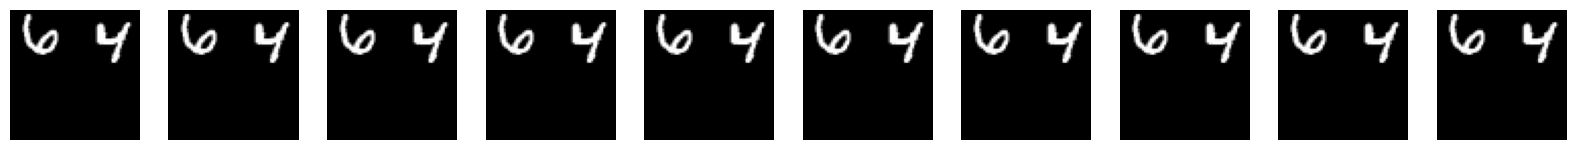

Model-predicted continuation:


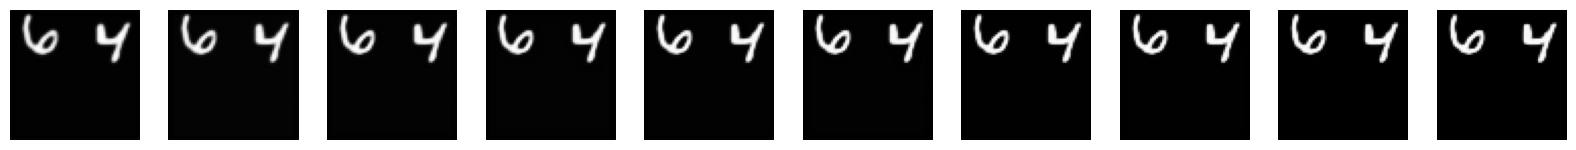

In [11]:
test_seq = video_dataset[0].unsqueeze(0)  # [1, seq_len, 1, H, W]
context = test_seq[:, :VIDEO_CONTEXT_LEN]
ground_truth = test_seq[0, VIDEO_CONTEXT_LEN:, 0].numpy()
predicted = generate_video(video_model, context, n_future=VIDEO_SEQ_LEN - VIDEO_CONTEXT_LEN)[0, :, 0].cpu().numpy()

print("Ground truth continuation:")
show_images(torch.from_numpy(ground_truth).unsqueeze(1), ncols=10, cmap="gray")
print("Model-predicted continuation:")
show_images(torch.from_numpy(predicted).unsqueeze(1), ncols=10, cmap="gray")

gif_path = save_gif(predicted, "outputs/video/predicted.gif")
display(HTML(f'<img src="{gif_path}">'))


### 3.8 User Input → Output Demo


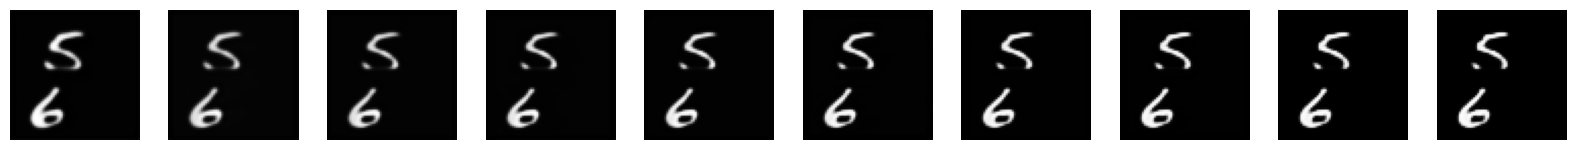

In [12]:
new_seq = video_dataset[np.random.randint(len(video_dataset))].unsqueeze(0)
context = new_seq[:, :VIDEO_CONTEXT_LEN]  # <- swap in your own [1, VIDEO_CONTEXT_LEN, 1, 64, 64] clip
future_pred = generate_video(video_model, context, n_future=10)[0, :, 0].cpu().numpy()
show_images(torch.from_numpy(future_pred).unsqueeze(1), ncols=10, cmap="gray")


### 3.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** predicting a plausible sequence of future video frames given only a short context clip, by learning spatio-temporal dynamics with a convolutional recurrent network.
- 💡 **Insight:** because ConvLSTM hidden state is spatial, the model implicitly learns object permanence and velocity -- it doesn't need to be told where the digits are, it tracks them through the hidden state.
- ⚠️ **Limitation:** MSE loss encourages **blurry** averages over plausible futures (a well-known issue in deterministic video prediction) -- the model hedges between possible bounce directions rather than committing to one.
- 🚀 **Scaling path:** replace the deterministic decoder with a stochastic one (VAE-style latent per step, or a video diffusion model as in 3.5b) to get sharp, diverse continuations, and add a text-conditioning tower for genuine text-to-video generation.


---
## This notebook is part of a series

This model solved the problem of: **predicting a plausible sequence of future video frames from a short context clip**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
